In [2]:

import numpy as np

# Define the computational basis states |0> and |1>.
zero = np.array([1, 0], dtype=complex)
one = np.array([0, 1], dtype=complex)

# Prepare the |+> superposition state.
psi = (zero + one) / np.sqrt(2)

# Construct the density matrix: rho = |psi><psi|.
rho = np.outer(psi, np.conjugate(psi))

# Calculate measurement probabilities in the Z basis.
prob_zero = np.abs(psi[0]) ** 2
prob_one = np.abs(psi[1]) ** 2

# Verify that the density matrix is normalized.
trace = np.trace(rho)

print("Initial quantum state:")
print(psi)

print("\nDensity matrix:")
print(rho)

print("\nMeasurement probabilities:")
print(f"P(|0>) = {prob_zero:.4f}")
print(f"P(|1>) = {prob_one:.4f}")

print("\nTrace of density matrix:", trace)


Initial quantum state:
[0.70710678+0.j 0.70710678+0.j]

Density matrix:
[[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]

Measurement probabilities:
P(|0>) = 0.5000
P(|1>) = 0.5000

Trace of density matrix: (0.9999999999999998+0j)


In [3]:
psi = (zero + one) / np.sqrt(2)

In [4]:
rho = np.outer(psi, np.conjugate(psi))

In [5]:

# Step 2: Depolarizing noise simulation

# Define the depolarizing noise channel.
def depolarizing_noise(rho, p):
    # Identity matrix with the same dimension as rho.
    identity = np.eye(2, dtype=complex)

    # Apply the depolarizing noise equation.
    noisy_rho = (1 - p) * rho + p * identity / 2

    return noisy_rho


# Test the channel at 40% noise strength.
p = 0.4

# Apply noise to our original |+> state.
rho_noisy = depolarizing_noise(rho, p)

# Fidelity with the original pure state.
fidelity = np.real(np.vdot(psi, rho_noisy @ psi))

print("Noise strength:", p)
print("\nOriginal density matrix:")
print(rho)

print("\nNoisy density matrix:")
print(rho_noisy)

print("\nState fidelity:", round(fidelity, 4))
print("Trace:", np.trace(rho_noisy))


Noise strength: 0.4

Original density matrix:
[[0.5+0.j 0.5+0.j]
 [0.5+0.j 0.5+0.j]]

Noisy density matrix:
[[0.5+0.j 0.3+0.j]
 [0.3+0.j 0.5+0.j]]

State fidelity: 0.8
Trace: (0.9999999999999999+0j)


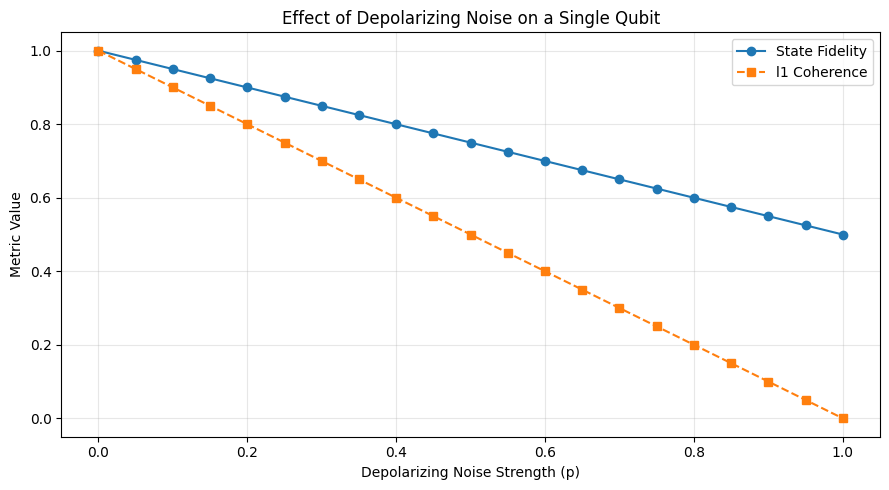


Noise Strength | Fidelity | Coherence
------------------------------------------
0.00           1.0000      1.0000
0.25           0.8750      0.7500
0.50           0.7500      0.5000
0.75           0.6250      0.2500
1.00           0.5000      0.0000


In [6]:

# Step 3: Investigate how depolarizing noise affects fidelity.

import matplotlib.pyplot as plt

# Generate 21 noise strengths between 0 and 1.
noise_levels = np.linspace(0, 1, 21)

# Store the fidelity and coherence measurements.
fidelity_values = []
coherence_values = []

for p in noise_levels:
    # Apply depolarizing noise to the initial state.
    noisy_state = depolarizing_noise(rho, p)

    # Calculate fidelity with the original |+> state.
    fidelity = np.real(np.vdot(psi, noisy_state @ psi))

    # Measure l1 coherence using off-diagonal elements.
    coherence = (
        np.abs(noisy_state[0, 1]) +
        np.abs(noisy_state[1, 0])
    )

    fidelity_values.append(fidelity)
    coherence_values.append(coherence)

# Plot both metrics against noise strength.
plt.figure(figsize=(9, 5))

plt.plot(noise_levels, fidelity_values,
         marker="o", label="State Fidelity")

plt.plot(noise_levels, coherence_values,
         marker="s", linestyle="--", label="l1 Coherence")

plt.xlabel("Depolarizing Noise Strength (p)")
plt.ylabel("Metric Value")
plt.title("Effect of Depolarizing Noise on a Single Qubit")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the graph for the seminar report and PPT.
plt.savefig("depolarizing_noise_analysis.png", dpi=300)

plt.show()

# Print selected results.
print("\nNoise Strength | Fidelity | Coherence")
print("-" * 42)

for i in range(0, len(noise_levels), 5):
    print(
        f"{noise_levels[i]:.2f}           "
        f"{fidelity_values[i]:.4f}      "
        f"{coherence_values[i]:.4f}"
    )


In [7]:

# Step 4: Phase damping noise simulation

def phase_damping_noise(rho, gamma):
    # Validate the noise parameter.
    if not 0 <= gamma <= 1:
        raise ValueError("gamma must be between 0 and 1")

    # Kraus operators for the phase damping channel.
    K0 = np.array([
        [1, 0],
        [0, np.sqrt(1 - gamma)]
    ], dtype=complex)

    K1 = np.array([
        [0, 0],
        [0, np.sqrt(gamma)]
    ], dtype=complex)

    # Apply the quantum channel using Kraus operators.
    noisy_rho = (
        K0 @ rho @ K0.conj().T +
        K1 @ rho @ K1.conj().T
    )

    return noisy_rho


# Test phase damping at gamma = 0.6.
gamma = 0.6
rho_phase = phase_damping_noise(rho, gamma)

# Calculate fidelity with the initial |+> state.
phase_fidelity = np.real(np.vdot(psi, rho_phase @ psi))

# Calculate l1 coherence.
phase_coherence = (
    np.abs(rho_phase[0, 1]) +
    np.abs(rho_phase[1, 0])
)

print("Phase damping strength:", gamma)
print("\nNoisy density matrix:")
print(rho_phase)

print("\nMeasurement probabilities:")
print(f"P(|0>) = {rho_phase[0, 0].real:.4f}")
print(f"P(|1>) = {rho_phase[1, 1].real:.4f}")

print("\nState fidelity:", round(phase_fidelity, 4))
print("l1 coherence:", round(phase_coherence, 4))
print("Trace:", np.trace(rho_phase))


Phase damping strength: 0.6

Noisy density matrix:
[[0.5       +0.j 0.31622777+0.j]
 [0.31622777+0.j 0.5       +0.j]]

Measurement probabilities:
P(|0>) = 0.5000
P(|1>) = 0.5000

State fidelity: 0.8162
l1 coherence: 0.6325
Trace: (0.9999999999999998+0j)


In [8]:

# Step 5: Amplitude damping noise simulation

def amplitude_damping_noise(rho, gamma):
    # Ensure gamma is a valid noise strength.
    if not 0 <= gamma <= 1:
        raise ValueError("gamma must be between 0 and 1")

    # K0 represents no energy relaxation.
    K0 = np.array([
        [1, 0],
        [0, np.sqrt(1 - gamma)]
    ], dtype=complex)

    # K1 represents relaxation from |1> to |0>.
    K1 = np.array([
        [0, np.sqrt(gamma)],
        [0, 0]
    ], dtype=complex)

    # Apply the amplitude damping channel.
    noisy_rho = (
        K0 @ rho @ K0.conj().T +
        K1 @ rho @ K1.conj().T
    )

    return noisy_rho


# Apply amplitude damping with gamma = 0.6.
gamma = 0.6
rho_amplitude = amplitude_damping_noise(rho, gamma)

# Calculate fidelity with the initial |+> state.
amplitude_fidelity = np.real(
    np.vdot(psi, rho_amplitude @ psi)
)

# Calculate l1 coherence.
amplitude_coherence = (
    np.abs(rho_amplitude[0, 1]) +
    np.abs(rho_amplitude[1, 0])
)

print("Amplitude damping strength:", gamma)
print("\nNoisy density matrix:")
print(rho_amplitude)

print("\nMeasurement probabilities:")
print(f"P(|0>) = {rho_amplitude[0, 0].real:.4f}")
print(f"P(|1>) = {rho_amplitude[1, 1].real:.4f}")

print("\nState fidelity:", round(amplitude_fidelity, 4))
print("l1 coherence:", round(amplitude_coherence, 4))
print("Trace:", np.trace(rho_amplitude))


Amplitude damping strength: 0.6

Noisy density matrix:
[[0.8       +0.j 0.31622777+0.j]
 [0.31622777+0.j 0.2       +0.j]]

Measurement probabilities:
P(|0>) = 0.8000
P(|1>) = 0.2000

State fidelity: 0.8162
l1 coherence: 0.6325
Trace: (0.9999999999999998+0j)


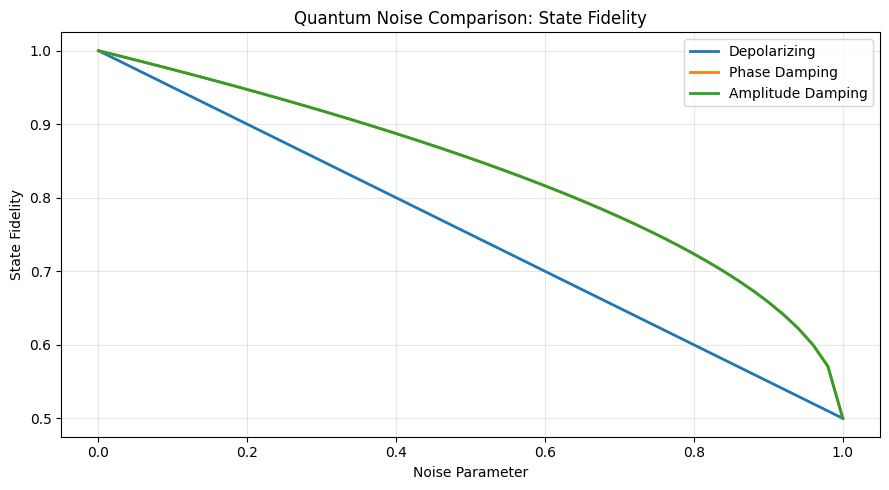

Saved: quantum_noise_fidelity_comparison.png


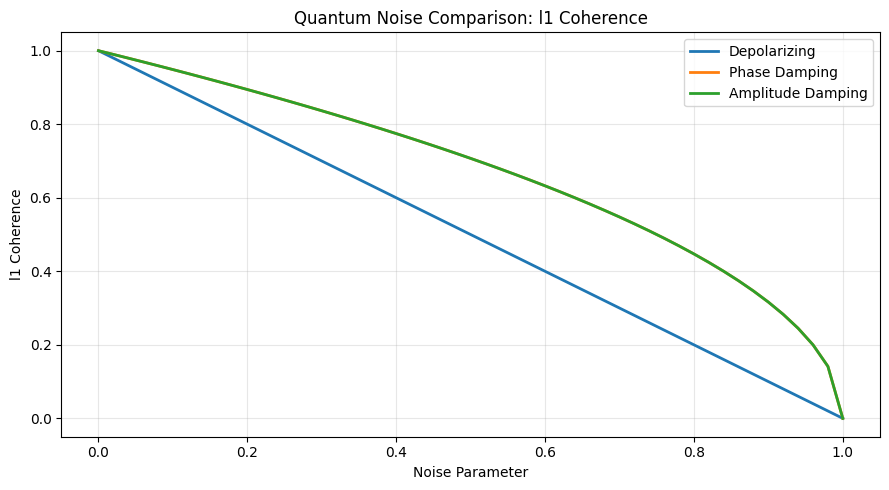

Saved: quantum_noise_coherence_comparison.png


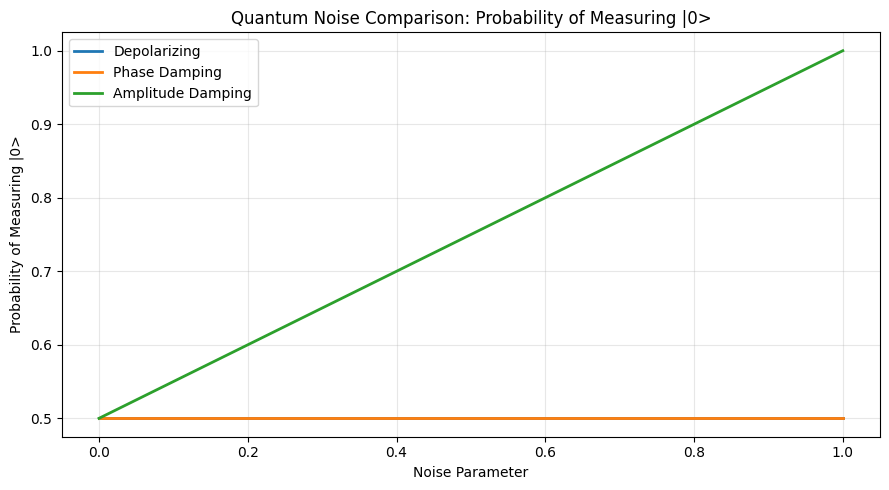

Saved: quantum_noise_p0_comparison.png

COMPARISON AT NOISE PARAMETER = 0.6
-----------------------------------------------------------------
Noise Model          Fidelity     Coherence    P(|0>)
Depolarizing         0.7000       0.4000       0.5000
Phase Damping        0.8162       0.6325       0.5000
Amplitude Damping    0.8162       0.6325       0.8000


In [9]:

# Step 6: Compare all three quantum noise models.

import matplotlib.pyplot as plt
import numpy as np

# Use the same noise parameter range for all channels.
noise_levels = np.linspace(0, 1, 51)

# Store results separately for each channel.
results = {
    "Depolarizing": {"fidelity": [], "coherence": [], "p0": []},
    "Phase Damping": {"fidelity": [], "coherence": [], "p0": []},
    "Amplitude Damping": {"fidelity": [], "coherence": [], "p0": []}
}

# Map each noise model to its corresponding function.
noise_models = {
    "Depolarizing": depolarizing_noise,
    "Phase Damping": phase_damping_noise,
    "Amplitude Damping": amplitude_damping_noise
}

for p in noise_levels:
    for name, noise_function in noise_models.items():
        # Apply the selected channel to the SAME initial state.
        noisy_state = noise_function(rho, p)

        # Calculate fidelity with the original pure state.
        fidelity = np.real(np.vdot(psi, noisy_state @ psi))

        # Calculate l1 coherence in the computational basis.
        coherence = (
            np.abs(noisy_state[0, 1]) +
            np.abs(noisy_state[1, 0])
        )

        # Extract probability of measuring |0>.
        p0 = np.real(noisy_state[0, 0])

        # Save the measurements for later analysis.
        results[name]["fidelity"].append(fidelity)
        results[name]["coherence"].append(coherence)
        results[name]["p0"].append(p0)


# Create a separate plot for each metric.
metrics = [
    ("fidelity", "State Fidelity"),
    ("coherence", "l1 Coherence"),
    ("p0", "Probability of Measuring |0>")
]

for metric, ylabel in metrics:
    plt.figure(figsize=(9, 5))

    for name in noise_models:
        plt.plot(
            noise_levels,
            results[name][metric],
            linewidth=2,
            label=name
        )

    plt.xlabel("Noise Parameter")
    plt.ylabel(ylabel)
    plt.title(f"Quantum Noise Comparison: {ylabel}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    # Save each graph for the seminar report.
    filename = f"quantum_noise_{metric}_comparison.png"
    plt.savefig(filename, dpi=300)
    plt.show()

    print("Saved:", filename)


# Print a numerical comparison at noise strength 0.6.
index = np.argmin(np.abs(noise_levels - 0.6))

print("\nCOMPARISON AT NOISE PARAMETER = 0.6")
print("-" * 65)
print(f"{'Noise Model':<20} {'Fidelity':<12} {'Coherence':<12} {'P(|0>)'}")

for name in noise_models:
    print(
        f"{name:<20} "
        f"{results[name]['fidelity'][index]:<12.4f} "
        f"{results[name]['coherence'][index]:<12.4f} "
        f"{results[name]['p0'][index]:.4f}"
    )


In [10]:

# Step 7: Validate the quantum noise simulation.

import numpy as np

def validate_density_matrix(state, tolerance=1e-10):
    # Check whether the matrix is Hermitian.
    hermitian = np.allclose(
        state, state.conj().T, atol=tolerance
    )

    # Check whether the trace equals one.
    normalized = np.isclose(
        np.trace(state), 1.0, atol=tolerance
    )

    # Compute eigenvalues of the Hermitian matrix.
    eigenvalues = np.linalg.eigvalsh(state)

    # Allow tiny negative values caused by rounding.
    positive = np.all(eigenvalues >= -tolerance)

    return hermitian, normalized, positive


# Test all three channels at multiple noise strengths.
test_levels = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

print("QUANTUM STATE VALIDATION")
print("-" * 60)

for name, channel in noise_models.items():
    all_valid = True

    for strength in test_levels:
        # Generate a noisy density matrix.
        state = channel(rho, strength)

        # Validate its mathematical properties.
        checks = validate_density_matrix(state)

        if not all(checks):
            all_valid = False

    status = "PASS" if all_valid else "FAIL"
    print(f"{name:<20}: {status}")


# Verify the analytical predictions at p = 0.6.
p = 0.6

expected_fidelity = {
    "Depolarizing": 1 - p / 2,
    "Phase Damping": (1 + np.sqrt(1 - p)) / 2,
    "Amplitude Damping": (1 + np.sqrt(1 - p)) / 2
}

print("\nANALYTICAL FIDELITY CHECK")
print("-" * 60)

for name, channel in noise_models.items():
    state = channel(rho, p)

    # Calculate fidelity from the simulated state.
    measured = np.real(np.vdot(psi, state @ psi))

    # Compare against the theoretical expression.
    expected = expected_fidelity[name]

    assert np.isclose(measured, expected, atol=1e-10)

    print(f"{name:<20}: PASS ({measured:.4f})")

print("\nAll analytical checks passed.")


QUANTUM STATE VALIDATION
------------------------------------------------------------
Depolarizing        : PASS
Phase Damping       : PASS
Amplitude Damping   : PASS

ANALYTICAL FIDELITY CHECK
------------------------------------------------------------
Depolarizing        : PASS (0.7000)
Phase Damping       : PASS (0.8162)
Amplitude Damping   : PASS (0.8162)

All analytical checks passed.


In [11]:

# Export all numerical results as a CSV file.

import pandas as pd

records = []

for name in noise_models:
    for i, strength in enumerate(noise_levels):
        records.append({
            "Noise_Model": name,
            "Noise_Strength": strength,
            "Fidelity": results[name]["fidelity"][i],
            "Coherence": results[name]["coherence"][i],
            "Probability_0": results[name]["p0"][i]
        })

# Create a structured results table.
df = pd.DataFrame(records)

# Save all experimental measurements.
df.to_csv("quantum_noise_results.csv", index=False)

print("Results exported successfully.")
print("Total records:", len(df))
print(df.head())


Results exported successfully.
Total records: 153
    Noise_Model  Noise_Strength  Fidelity  Coherence  Probability_0
0  Depolarizing            0.00      1.00       1.00            0.5
1  Depolarizing            0.02      0.99       0.98            0.5
2  Depolarizing            0.04      0.98       0.96            0.5
3  Depolarizing            0.06      0.97       0.94            0.5
4  Depolarizing            0.08      0.96       0.92            0.5
